In [7]:
# ============================================================
# X-SatNet
# Explainable Cross-Dataset Satellite Scene Classification
# Conference Version
# ============================================================

import os
import gc
import cv2
import time
import json
import math
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

import torchvision

warnings.filterwarnings("ignore")

plt.rcParams["figure.figsize"] = (8, 6)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)

torch.cuda.manual_seed_all(SEED)

print("=" * 60)
print("Libraries Imported Successfully")
print("=" * 60)

Libraries Imported Successfully


In [8]:
# ============================================================
# Cell 2 : GPU Detection & Performance Configuration
# ============================================================

print("=" * 60)
print("Checking Hardware Configuration")
print("=" * 60)

# ---------------------------
# Device Selection
# ---------------------------

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Device             : {DEVICE}")

if torch.cuda.is_available():

    print(f"GPU Name           : {torch.cuda.get_device_name(0)}")
    print(f"CUDA Version       : {torch.version.cuda}")

    gpu_properties = torch.cuda.get_device_properties(0)

    print(f"GPU Memory         : {gpu_properties.total_memory / 1024**3:.2f} GB")
    print(f"Multiprocessors    : {gpu_properties.multi_processor_count}")

    # Performance Optimizations
    torch.backends.cudnn.benchmark = True
    torch.backends.cudnn.enabled = True

    # Mixed Precision Available?
    print("Mixed Precision    : Enabled")

else:
    print("Running on CPU")

print("=" * 60)

Checking Hardware Configuration
Device             : cuda
GPU Name           : NVIDIA GeForce RTX 4050 Laptop GPU
CUDA Version       : 13.2
GPU Memory         : 6.00 GB
Multiprocessors    : 20
Mixed Precision    : Enabled


In [9]:
# ============================================================
# Cell 3 : Project Configuration
# ============================================================

from pathlib import Path

# -----------------------------
# Project Information
# -----------------------------

PROJECT_NAME = "X-SatNet"

# -----------------------------
# Dataset Paths
# -----------------------------

ROOT_DIR = Path(r"F:\PAPER\CONFERENCES\XSatNet CONFERENCE 16\working")

DATASET_DIR = ROOT_DIR / "Dataset"

EUROSAT_DIR = DATASET_DIR / "EuroSAT" / "EuroSAT"

UCMERCED_DIR = DATASET_DIR / "UCMerced_LandUse" / "Images"

# -----------------------------
# Output Directories
# -----------------------------

OUTPUT_DIR = ROOT_DIR / "Outputs"

CHECKPOINT_DIR = OUTPUT_DIR / "Checkpoints"
PLOT_DIR = OUTPUT_DIR / "Plots"
LOG_DIR = OUTPUT_DIR / "Logs"
METRIC_DIR = OUTPUT_DIR / "Metrics"
GRADCAM_DIR = OUTPUT_DIR / "GradCAM"
SHAP_DIR = OUTPUT_DIR / "SHAP"
BENCHMARK_DIR = OUTPUT_DIR / "Benchmark"
PREDICTION_DIR = OUTPUT_DIR / "Predictions"

directories = [
    OUTPUT_DIR,
    CHECKPOINT_DIR,
    PLOT_DIR,
    LOG_DIR,
    METRIC_DIR,
    GRADCAM_DIR,
    SHAP_DIR,
    BENCHMARK_DIR,
    PREDICTION_DIR
]

for directory in directories:
    directory.mkdir(parents=True, exist_ok=True)

# -----------------------------
# Training Configuration
# -----------------------------

IMAGE_SIZE = 224

BATCH_SIZE = 32          # Optimized for RTX 3050 6GB

NUM_WORKERS = 0

EPOCHS = 40

LEARNING_RATE = 3e-4

WEIGHT_DECAY = 1e-4

VALIDATION_SPLIT = 0.15

TEST_SPLIT = 0.15

RANDOM_STATE = 42

PIN_MEMORY = True

PERSISTENT_WORKERS = True

# -----------------------------
# Mixed Precision
# -----------------------------

USE_AMP = True

# -----------------------------
# Model Names
# -----------------------------

MAIN_MODEL = "tf_efficientnetv2_s"

BASELINE_MODEL = "mobilenetv3_large_100"

COMPARISON_MODEL = "convnext_tiny"

# -----------------------------
# Display Configuration
# -----------------------------

print("="*70)
print("Project Configuration")
print("="*70)

print(f"Project Name      : {PROJECT_NAME}")
print(f"Dataset Folder    : {DATASET_DIR}")
print(f"EuroSAT Folder    : {EUROSAT_DIR}")
print(f"UC Merced Folder  : {UCMERCED_DIR}")

print("\nTraining Configuration")

print(f"Image Size        : {IMAGE_SIZE}")
print(f"Batch Size        : {BATCH_SIZE}")
print(f"Epochs            : {EPOCHS}")
print(f"Learning Rate     : {LEARNING_RATE}")
print(f"Mixed Precision   : {USE_AMP}")

print("\nOutput Folder")

print(OUTPUT_DIR)

print("="*70)

Project Configuration
Project Name      : X-SatNet
Dataset Folder    : F:\PAPER\CONFERENCES\XSatNet CONFERENCE 16\working\Dataset
EuroSAT Folder    : F:\PAPER\CONFERENCES\XSatNet CONFERENCE 16\working\Dataset\EuroSAT\EuroSAT
UC Merced Folder  : F:\PAPER\CONFERENCES\XSatNet CONFERENCE 16\working\Dataset\UCMerced_LandUse\Images

Training Configuration
Image Size        : 224
Batch Size        : 32
Epochs            : 40
Learning Rate     : 0.0003
Mixed Precision   : True

Output Folder
F:\PAPER\CONFERENCES\XSatNet CONFERENCE 16\working\Outputs


In [10]:
# ============================================================
# Cell 4 : Dataset Exploration
# ============================================================

from collections import defaultdict

print("=" * 70)
print("DATASET EXPLORATION")
print("=" * 70)

# ----------------------------------------------------------
# Function to Explore Dataset
# ----------------------------------------------------------

def explore_dataset(dataset_path, dataset_name):

    print(f"\nExploring {dataset_name}")
    print("-" * 60)

    class_names = sorted(
        [folder.name for folder in dataset_path.iterdir() if folder.is_dir()]
    )

    dataset_info = []

    total_images = 0

    for cls in class_names:

        class_path = dataset_path / cls

        image_count = len([
            img for img in class_path.iterdir()
            if img.suffix.lower() in [".jpg", ".jpeg", ".png", ".tif", ".bmp"]
        ])

        dataset_info.append((cls, image_count))

        total_images += image_count

    df = pd.DataFrame(dataset_info,
                      columns=["Class", "Images"])

    print(df)

    print("\nNumber of Classes :", len(class_names))
    print("Total Images      :", total_images)

    return df


# ----------------------------------------------------------
# Explore EuroSAT
# ----------------------------------------------------------

eurosat_df = explore_dataset(
    EUROSAT_DIR,
    "EuroSAT"
)

# ----------------------------------------------------------
# Explore UC Merced
# ----------------------------------------------------------

ucmerced_df = explore_dataset(
    UCMERCED_DIR,
    "UC Merced"
)

print("\n")
print("=" * 70)
print("Dataset Exploration Completed Successfully")
print("=" * 70)

DATASET EXPLORATION

Exploring EuroSAT
------------------------------------------------------------
                  Class  Images
0            AnnualCrop    3000
1                Forest    3000
2  HerbaceousVegetation    3000
3               Highway    2500
4            Industrial    2500
5               Pasture    2000
6         PermanentCrop    2500
7           Residential    3000
8                 River    2500
9               SeaLake    3000

Number of Classes : 10
Total Images      : 27000

Exploring UC Merced
------------------------------------------------------------
                Class  Images
0        agricultural     100
1            airplane     100
2     baseballdiamond     100
3               beach     100
4           buildings     100
5           chaparral     100
6    denseresidential     100
7              forest     100
8             freeway     100
9          golfcourse     100
10             harbor     100
11       intersection     100
12  mediumresidential     

In [11]:
# ============================================================
# Cell 5 : Unified Class Mapping
# ============================================================

print("=" * 70)
print("UNIFIED CLASS MAPPING")
print("=" * 70)

# -----------------------------------------------------------
# Unified Mapping
# -----------------------------------------------------------

UNIFIED_MAPPING = {

    "Agriculture": [
        ("EuroSAT", "AnnualCrop"),
        ("EuroSAT", "PermanentCrop"),
        ("UCMerced", "agricultural")
    ],

    "Forest": [
        ("EuroSAT", "Forest"),
        ("UCMerced", "forest")
    ],

    "Vegetation": [
        ("EuroSAT", "HerbaceousVegetation"),
        ("EuroSAT", "Pasture"),
        ("UCMerced", "chaparral")
    ],

    "Residential": [
        ("EuroSAT", "Residential"),
        ("UCMerced", "denseresidential"),
        ("UCMerced", "mediumresidential"),
        ("UCMerced", "sparseresidential"),
        ("UCMerced", "mobilehomepark")
    ],

    "Highway": [
        ("EuroSAT", "Highway"),
        ("UCMerced", "freeway"),
        ("UCMerced", "intersection"),
        ("UCMerced", "overpass")
    ],

    "Industrial": [
        ("EuroSAT", "Industrial"),
        ("UCMerced", "buildings"),
        ("UCMerced", "storagetanks")
    ],

    "Water": [
        ("EuroSAT", "River"),
        ("EuroSAT", "SeaLake"),
        ("UCMerced", "river"),
        ("UCMerced", "harbor"),
        ("UCMerced", "beach")
    ]
}

print("\nUnified Classes\n")

for cls, members in UNIFIED_MAPPING.items():

    print(f"{cls}")

    for dataset_name, original_class in members:

        print(f"   └── {dataset_name:<10} : {original_class}")

    print()

print("=" * 70)
print(f"Total Unified Classes : {len(UNIFIED_MAPPING)}")
print("=" * 70)

UNIFIED CLASS MAPPING

Unified Classes

Agriculture
   └── EuroSAT    : AnnualCrop
   └── EuroSAT    : PermanentCrop
   └── UCMerced   : agricultural

Forest
   └── EuroSAT    : Forest
   └── UCMerced   : forest

Vegetation
   └── EuroSAT    : HerbaceousVegetation
   └── EuroSAT    : Pasture
   └── UCMerced   : chaparral

Residential
   └── EuroSAT    : Residential
   └── UCMerced   : denseresidential
   └── UCMerced   : mediumresidential
   └── UCMerced   : sparseresidential
   └── UCMerced   : mobilehomepark

Highway
   └── EuroSAT    : Highway
   └── UCMerced   : freeway
   └── UCMerced   : intersection
   └── UCMerced   : overpass

Industrial
   └── EuroSAT    : Industrial
   └── UCMerced   : buildings
   └── UCMerced   : storagetanks

Water
   └── EuroSAT    : River
   └── EuroSAT    : SeaLake
   └── UCMerced   : river
   └── UCMerced   : harbor
   └── UCMerced   : beach

Total Unified Classes : 7


In [12]:
# ============================================================
# Cell 6 : Create Unified Dataset
# ============================================================

import shutil

print("=" * 70)
print("CREATING UNIFIED DATASET")
print("=" * 70)

# -----------------------------------------------------------
# Unified Dataset Folder
# -----------------------------------------------------------

UNIFIED_DATASET_DIR = DATASET_DIR / "UnifiedDataset"
UNIFIED_DATASET_DIR.mkdir(exist_ok=True)

# -----------------------------------------------------------
# Create Class Folders
# -----------------------------------------------------------

for unified_class in UNIFIED_MAPPING.keys():
    (UNIFIED_DATASET_DIR / unified_class).mkdir(parents=True, exist_ok=True)

# -----------------------------------------------------------
# Metadata
# -----------------------------------------------------------

metadata = []

# -----------------------------------------------------------
# Copy Images
# -----------------------------------------------------------

for unified_class, mappings in UNIFIED_MAPPING.items():

    print(f"\nProcessing : {unified_class}")

    image_counter = 0

    for dataset_name, original_class in mappings:

        if dataset_name == "EuroSAT":
            source_folder = EUROSAT_DIR / original_class
        else:
            source_folder = UCMERCED_DIR / original_class

        if not source_folder.exists():
            print(f"Missing Folder : {source_folder}")
            continue

        images = list(source_folder.glob("*"))

        for img_path in tqdm(images, leave=False):

            if img_path.suffix.lower() not in [".jpg", ".jpeg", ".png", ".tif", ".bmp"]:
                continue

            image_counter += 1

            new_name = f"{dataset_name}_{image_counter:06d}{img_path.suffix.lower()}"

            destination = UNIFIED_DATASET_DIR / unified_class / new_name

            shutil.copy2(img_path, destination)

            metadata.append({
                "filename": new_name,
                "unified_class": unified_class,
                "source_dataset": dataset_name,
                "original_class": original_class
            })

# -----------------------------------------------------------
# Save Metadata
# -----------------------------------------------------------

metadata_df = pd.DataFrame(metadata)

metadata_csv = OUTPUT_DIR / "unified_dataset_metadata.csv"

metadata_df.to_csv(metadata_csv, index=False)

print("\n")

print("=" * 70)
print("Unified Dataset Created Successfully")
print("=" * 70)

print(f"Location : {UNIFIED_DATASET_DIR}")

print(f"Total Images : {len(metadata_df)}")

print(f"Metadata CSV : {metadata_csv}")

CREATING UNIFIED DATASET

Processing : Agriculture



Processing : Forest



Processing : Vegetation



Processing : Residential



Processing : Highway



Processing : Industrial



Processing : Water




Unified Dataset Created Successfully
Location : F:\PAPER\CONFERENCES\XSatNet CONFERENCE 16\working\Dataset\UnifiedDataset
Total Images : 28500
Metadata CSV : F:\PAPER\CONFERENCES\XSatNet CONFERENCE 16\working\Outputs\unified_dataset_metadata.csv


UNIFIED DATASET VERIFICATION


,Unified Class,Images
0,Agriculture,5600
1,Forest,3100
2,Highway,2800
3,Industrial,2700
4,Residential,3400
5,Vegetation,5100
6,Water,5800




Total Images : 28500


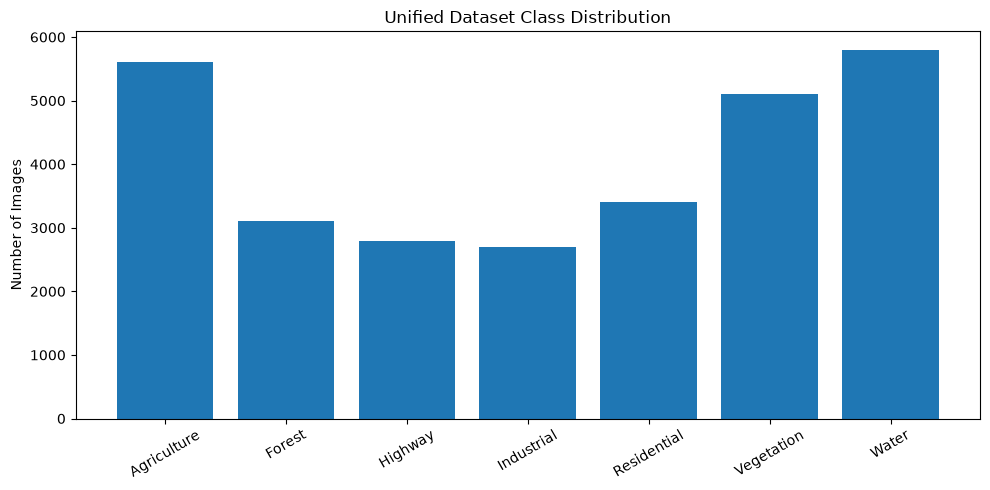



source_dataset
EuroSAT     27000
UCMerced     1500
Name: count, dtype: int64


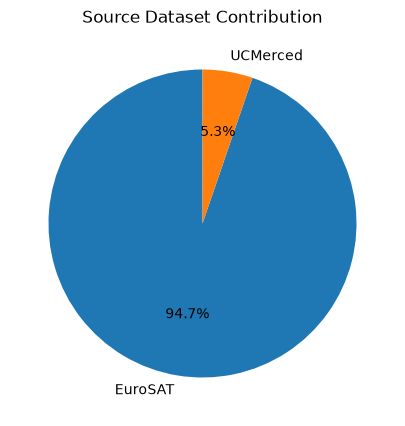


Duplicate Filenames : 21900
Missing Files : 0
Verification Completed Successfully


In [13]:
# ============================================================
# Cell 7 : Unified Dataset Verification & Visualization
# ============================================================

from collections import Counter

print("=" * 70)
print("UNIFIED DATASET VERIFICATION")
print("=" * 70)

# -----------------------------------------------------------
# Count Images Per Unified Class
# -----------------------------------------------------------
UNIFIED_DATASET_DIR = DATASET_DIR / "UnifiedDataset"
class_counts = {}

for class_dir in sorted(UNIFIED_DATASET_DIR.iterdir()):

    if class_dir.is_dir():

        count = len([
            x for x in class_dir.iterdir()
            if x.suffix.lower() in [".jpg", ".jpeg", ".png", ".tif", ".bmp"]
        ])

        class_counts[class_dir.name] = count

counts_df = pd.DataFrame(
    list(class_counts.items()),
    columns=["Unified Class", "Images"]
)

display(counts_df)

print("\n")

print("Total Images :", counts_df["Images"].sum())

# -----------------------------------------------------------
# Plot Distribution
# -----------------------------------------------------------

plt.figure(figsize=(10,5))

plt.bar(
    counts_df["Unified Class"],
    counts_df["Images"]
)

plt.xticks(rotation=30)

plt.title("Unified Dataset Class Distribution")

plt.ylabel("Number of Images")

plt.tight_layout()

plt.show()

# -----------------------------------------------------------
# Source Dataset Distribution
# -----------------------------------------------------------

source_counts = metadata_df["source_dataset"].value_counts()

print("\n")

print(source_counts)

plt.figure(figsize=(5,5))

plt.pie(
    source_counts,
    labels=source_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Source Dataset Contribution")

plt.show()

# -----------------------------------------------------------
# Duplicate Filename Check
# -----------------------------------------------------------

duplicates = metadata_df["filename"].duplicated().sum()

print("\nDuplicate Filenames :", duplicates)

# -----------------------------------------------------------
# Missing File Check
# -----------------------------------------------------------

missing = 0

for _, row in metadata_df.iterrows():

    path = UNIFIED_DATASET_DIR / row["unified_class"] / row["filename"]

    if not path.exists():

        missing += 1

print("Missing Files :", missing)

print("=" * 70)
print("Verification Completed Successfully")
print("=" * 70)

In [14]:
# ============================================================
# Cell 8 : Create Stratified Train / Validation / Test Splits
# ============================================================

print("=" * 70)
print("CREATING STRATIFIED DATA SPLITS")
print("=" * 70)

records = []

# -----------------------------------------------------------
# Collect Image Paths
# -----------------------------------------------------------

for class_dir in sorted(UNIFIED_DATASET_DIR.iterdir()):

    if not class_dir.is_dir():
        continue

    class_name = class_dir.name

    for img_path in class_dir.iterdir():

        if img_path.suffix.lower() not in [".jpg", ".jpeg", ".png", ".tif", ".bmp"]:
            continue

        records.append({
            "filepath": str(img_path),
            "class": class_name
        })

dataset_df = pd.DataFrame(records)

print(f"Total Images Collected : {len(dataset_df)}")

# -----------------------------------------------------------
# Stratified Split
# -----------------------------------------------------------

train_df, temp_df = train_test_split(
    dataset_df,
    test_size=VALIDATION_SPLIT + TEST_SPLIT,
    stratify=dataset_df["class"],
    random_state=RANDOM_STATE
)

val_ratio = VALIDATION_SPLIT / (VALIDATION_SPLIT + TEST_SPLIT)

val_df, test_df = train_test_split(
    temp_df,
    test_size=1 - val_ratio,
    stratify=temp_df["class"],
    random_state=RANDOM_STATE
)

# -----------------------------------------------------------
# Save CSV Files
# -----------------------------------------------------------

train_csv = OUTPUT_DIR / "train_split.csv"
val_csv = OUTPUT_DIR / "val_split.csv"
test_csv = OUTPUT_DIR / "test_split.csv"

train_df.to_csv(train_csv, index=False)
val_df.to_csv(val_csv, index=False)
test_df.to_csv(test_csv, index=False)

print("\nTrain :", len(train_df))
print("Validation :", len(val_df))
print("Test :", len(test_df))

print("\nCSV files saved successfully.")

print(train_csv)
print(val_csv)
print(test_csv)

# -----------------------------------------------------------
# Verify No Leakage
# -----------------------------------------------------------

train_set = set(train_df["filepath"])
val_set = set(val_df["filepath"])
test_set = set(test_df["filepath"])

assert len(train_set & val_set) == 0
assert len(train_set & test_set) == 0
assert len(val_set & test_set) == 0

print("\n✓ No data leakage detected.")

print("=" * 70)
print("Data Splitting Completed Successfully")
print("=" * 70)

CREATING STRATIFIED DATA SPLITS
Total Images Collected : 28500

Train : 19950
Validation : 4275
Test : 4275

CSV files saved successfully.
F:\PAPER\CONFERENCES\XSatNet CONFERENCE 16\working\Outputs\train_split.csv
F:\PAPER\CONFERENCES\XSatNet CONFERENCE 16\working\Outputs\val_split.csv
F:\PAPER\CONFERENCES\XSatNet CONFERENCE 16\working\Outputs\test_split.csv

✓ No data leakage detected.
Data Splitting Completed Successfully


In [15]:
# ============================================================
# Cell 9 : Label Encoding & Class Weights
# ============================================================

from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

print("=" * 70)
print("LABEL ENCODING")
print("=" * 70)

# -----------------------------------------------------------
# Label Encoder
# -----------------------------------------------------------

label_encoder = LabelEncoder()

label_encoder.fit(train_df["class"])

train_df["label"] = label_encoder.transform(train_df["class"])
val_df["label"] = label_encoder.transform(val_df["class"])
test_df["label"] = label_encoder.transform(test_df["class"])

# -----------------------------------------------------------
# Class Names
# -----------------------------------------------------------

CLASS_NAMES = list(label_encoder.classes_)

NUM_CLASSES = len(CLASS_NAMES)

print("Number of Classes :", NUM_CLASSES)

print("\nClass Mapping")

for idx, cls in enumerate(CLASS_NAMES):
    print(f"{idx} -> {cls}")

# -----------------------------------------------------------
# Save Label Mapping
# -----------------------------------------------------------

label_mapping = {
    int(i): cls
    for i, cls in enumerate(CLASS_NAMES)
}

with open(OUTPUT_DIR / "label_mapping.json", "w") as f:
    json.dump(label_mapping, f, indent=4)

# -----------------------------------------------------------
# Compute Class Weights
# -----------------------------------------------------------

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_df["label"]),
    y=train_df["label"]
)

CLASS_WEIGHTS = torch.tensor(
    weights,
    dtype=torch.float32
).to(DEVICE)

print("\nClass Weights")

for cls, weight in zip(CLASS_NAMES, weights):
    print(f"{cls:15s} : {weight:.4f}")

print("=" * 70)
print("Label Encoding Completed")
print("=" * 70)

LABEL ENCODING
Number of Classes : 7

Class Mapping
0 -> Agriculture
1 -> Forest
2 -> Highway
3 -> Industrial
4 -> Residential
5 -> Vegetation
6 -> Water

Class Weights
Agriculture     : 0.7270
Forest          : 1.3134
Highway         : 1.4541
Industrial      : 1.5079
Residential     : 1.1975
Vegetation      : 0.7983
Water           : 0.7020
Label Encoding Completed


In [16]:
!pip install albumentations

   ---------------------------------------- 0.0/43.8 MB ? eta -:--:--
   ---------------------------------------- 0.3/43.8 MB ? eta -:--:--
   ---------------------------------------- 0.5/43.8 MB 1.1 MB/s eta 0:00:39
    --------------------------------------- 0.8/43.8 MB 1.2 MB/s eta 0:00:38
    --------------------------------------- 1.0/43.8 MB 1.2 MB/s eta 0:00:37
   - -------------------------------------- 1.3/43.8 MB 1.2 MB/s eta 0:00:37
   - -------------------------------------- 1.6/43.8 MB 1.2 MB/s eta 0:00:36
   - -------------------------------------- 1.8/43.8 MB 1.2 MB/s eta 0:00:36
   - -------------------------------------- 2.1/43.8 MB 1.2 MB/s eta 0:00:36
   -- ------------------------------------- 2.4/43.8 MB 1.2 MB/s eta 0:00:35
   -- ------------------------------------- 2.6/43.8 MB 1.2 MB/s eta 0:00:35
   -- ------------------------------------- 2.6/43.8 MB 1.2 MB/s eta 0:00:35
   -- ------------------------------------- 2.9/43.8 MB 1.2 MB/s eta 0:00:35
   -- -------

ERROR: Could not install packages due to an OSError: [WinError 5] Access is denied: 'C:\\Users\\cscpr\\AppData\\Local\\Programs\\Python\\Python314\\Lib\\site-packages\\cv2\\cv2.pyd'
Consider using the `--user` option or check the permissions.


[notice] A new release of pip is available: 26.1.2 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [18]:
# ============================================================
# Cell 10 : Data Augmentation & Preprocessing
# ============================================================

import albumentations as A
from albumentations.pytorch import ToTensorV2

print("=" * 70)
print("DATA AUGMENTATION PIPELINE")
print("=" * 70)

# -----------------------------------------------------------
# Training Transform
# -----------------------------------------------------------

train_transform = A.Compose([

    A.Resize(IMAGE_SIZE, IMAGE_SIZE),

    A.HorizontalFlip(p=0.5),

    A.VerticalFlip(p=0.5),

    A.RandomRotate90(p=0.5),

    A.Affine(
        scale=(0.9,1.1),
        translate_percent=(-0.05,0.05),
        rotate=(-20,20),
        border_mode=cv2.BORDER_REFLECT_101,
        p=0.5
    ),

    A.RandomBrightnessContrast(
        brightness_limit=0.2,
        contrast_limit=0.2,
        p=0.5
    ),

    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),

    ToTensorV2()

])

# -----------------------------------------------------------
# Validation/Test Transform
# -----------------------------------------------------------

valid_transform = A.Compose([

    A.Resize(IMAGE_SIZE, IMAGE_SIZE),

    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),

    ToTensorV2()

])

print("Training Augmentations")

for t in train_transform.transforms:
    print(" •", t)

print("\nValidation Augmentations")

for t in valid_transform.transforms:
    print(" •", t)

print("=" * 70)

DATA AUGMENTATION PIPELINE
Training Augmentations
 • Resize(p=1.0, area_for_downscale=None, height=224, interpolation=1, mask_interpolation=0, width=224)
 • HorizontalFlip(p=0.5)
 • VerticalFlip(p=0.5)
 • RandomRotate90(p=0.5)
 • Affine(p=0.5, balanced_scale=False, border_mode=4, fill=0.0, fill_mask=0.0, fit_output=False, interpolation=1, keep_ratio=False, mask_interpolation=0, rotate=(-20.0, 20.0), rotate_method='largest_box', scale={'x': (0.9, 1.1), 'y': (0.9, 1.1)}, shear={'x': (0.0, 0.0), 'y': (0.0, 0.0)}, translate_percent={'x': (-0.05, 0.05), 'y': (-0.05, 0.05)}, translate_px=None)
 • RandomBrightnessContrast(p=0.5, brightness_by_max=True, brightness_limit=(-0.2, 0.2), contrast_limit=(-0.2, 0.2), ensure_safe_range=False)
 • Normalize(p=1.0, max_pixel_value=255.0, mean=(0.485, 0.456, 0.406), normalization='standard', std=(0.229, 0.224, 0.225))
 • ToTensorV2(p=1.0, transpose_mask=False)

Validation Augmentations
 • Resize(p=1.0, area_for_downscale=None, height=224, interpolation=1,

In [19]:
# ============================================================
# Cell 11 : Custom PyTorch Dataset
# ============================================================

from torch.utils.data import Dataset
import cv2

print("=" * 70)
print("CREATING CUSTOM PYTORCH DATASET")
print("=" * 70)


class SatelliteDataset(Dataset):

    def __init__(self, dataframe, transform=None):

        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        image_path = self.df.loc[idx, "filepath"]
        label = int(self.df.loc[idx, "label"])

        # Read Image
        image = cv2.imread(image_path)

        if image is None:
            raise RuntimeError(f"Unable to load image:\n{image_path}")

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # Apply Augmentations
        if self.transform:

            augmented = self.transform(image=image)

            image = augmented["image"]

        return image, label


# -------------------------------------------------------
# Create Dataset Objects
# -------------------------------------------------------

train_dataset = SatelliteDataset(
    train_df,
    train_transform
)

val_dataset = SatelliteDataset(
    val_df,
    valid_transform
)

test_dataset = SatelliteDataset(
    test_df,
    valid_transform
)

print(f"Training Images   : {len(train_dataset):,}")
print(f"Validation Images : {len(val_dataset):,}")
print(f"Testing Images    : {len(test_dataset):,}")

print("=" * 70)
print("Dataset Successfully Created")
print("=" * 70)

CREATING CUSTOM PYTORCH DATASET
Training Images   : 19,950
Validation Images : 4,275
Testing Images    : 4,275
Dataset Successfully Created


In [20]:
# ============================================================
# Cell 12 : DataLoaders
# ============================================================

print("=" * 70)
print("CREATING DATALOADERS")
print("=" * 70)

from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
    drop_last=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
    drop_last=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
    drop_last=False
)

print(f"Training Batches   : {len(train_loader)}")
print(f"Validation Batches : {len(val_loader)}")
print(f"Testing Batches    : {len(test_loader)}")

print("=" * 70)
print("DataLoaders Ready")
print("=" * 70)

CREATING DATALOADERS
Training Batches   : 623
Validation Batches : 134
Testing Batches    : 134
DataLoaders Ready


VISUALIZING AUGMENTED TRAINING IMAGES


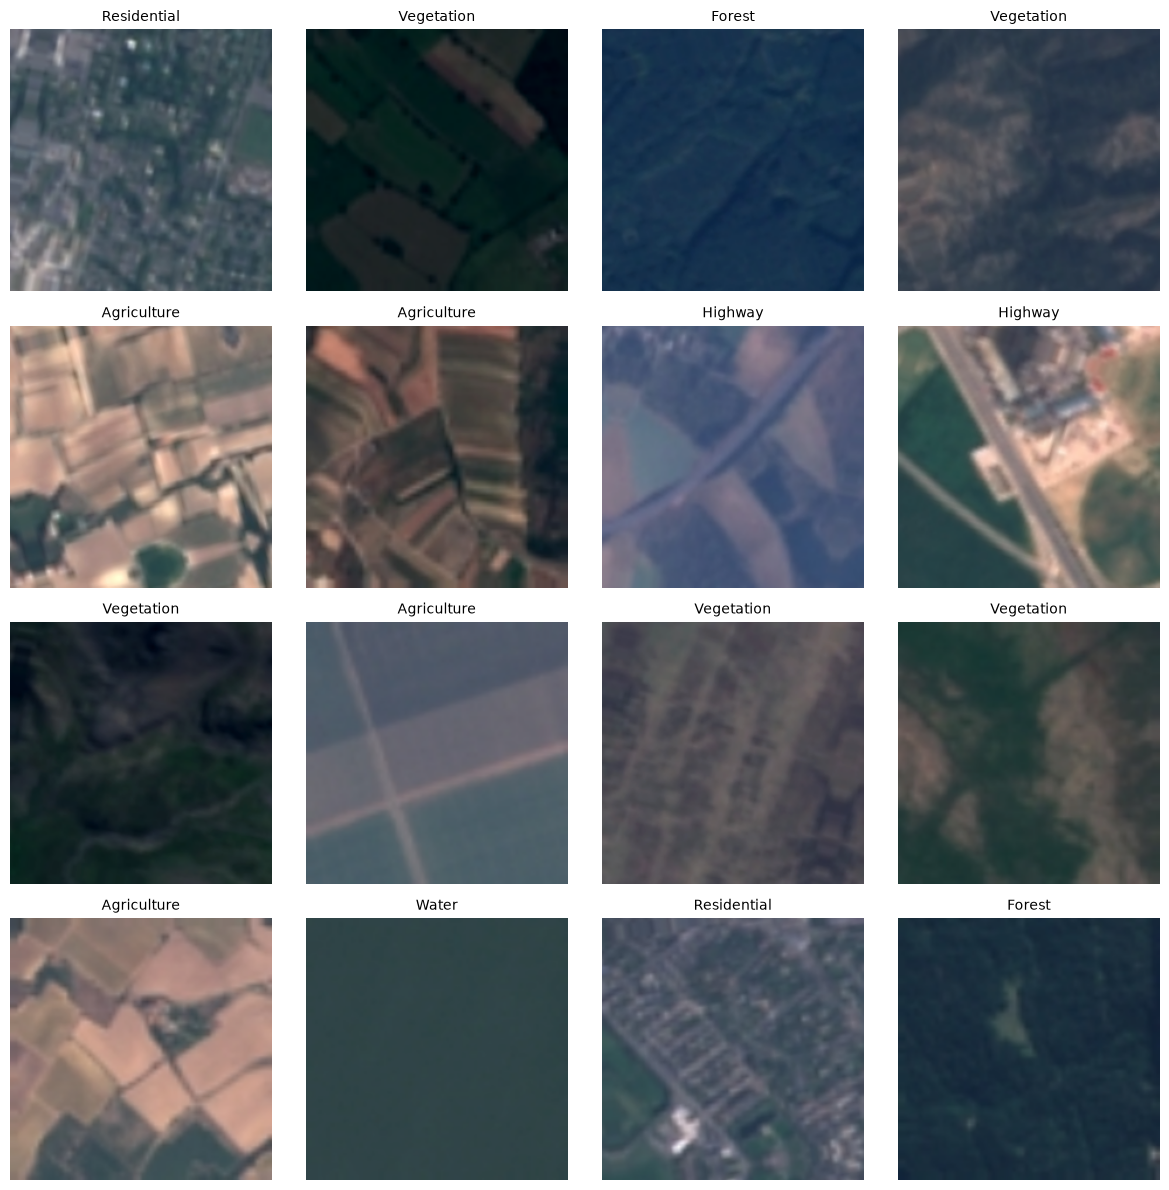

Visualization Completed


In [21]:
# ============================================================
# Cell 13 : Dataset Sanity Check
# ============================================================

print("=" * 70)
print("VISUALIZING AUGMENTED TRAINING IMAGES")
print("=" * 70)

import matplotlib.pyplot as plt

# -----------------------------------------------------------
# Reverse Normalization Function
# -----------------------------------------------------------

mean = np.array([0.485, 0.456, 0.406])
std  = np.array([0.229, 0.224, 0.225])

def denormalize(image):

    image = image.permute(1, 2, 0).cpu().numpy()

    image = (image * std) + mean

    image = np.clip(image, 0, 1)

    return image


# -----------------------------------------------------------
# Display 16 Samples
# -----------------------------------------------------------

fig, axes = plt.subplots(4, 4, figsize=(12, 12))

for ax in axes.flatten():

    idx = random.randint(0, len(train_dataset) - 1)

    image, label = train_dataset[idx]

    image = denormalize(image)

    class_name = CLASS_NAMES[label]

    ax.imshow(image)

    ax.set_title(class_name, fontsize=10)

    ax.axis("off")

plt.tight_layout()

plt.show()

print("=" * 70)
print("Visualization Completed")
print("=" * 70)

In [ ]:
!pip install timm

Defaulting to user installation because normal site-packages is not writeable


In [22]:
# ============================================================
# Cell 14 : EfficientNetV2-S
# ============================================================

import timm
import torch.nn as nn

print("=" * 70)
print("BUILDING EFFICIENTNETV2-S")
print("=" * 70)

MODEL_NAME = "tf_efficientnetv2_s"

model = timm.create_model(
    MODEL_NAME,
    pretrained=True,
    num_classes=NUM_CLASSES
)

model = model.to(DEVICE)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Model Name           : {MODEL_NAME}")
print(f"Total Parameters     : {total_params:,}")
print(f"Trainable Parameters : {trainable_params:,}")

print("=" * 70)
print("Model Ready")
print("=" * 70)

BUILDING EFFICIENTNETV2-S


Model Name           : tf_efficientnetv2_s
Total Parameters     : 20,186,455
Trainable Parameters : 20,186,455
Model Ready


In [23]:
# ============================================================
# Cell 15 : Loss Function, Optimizer, Scheduler
# ============================================================

import torch.nn as nn

print("=" * 70)
print("CONFIGURING TRAINING")
print("=" * 70)

# -----------------------------------------------------------
# Loss Function
# -----------------------------------------------------------

criterion = nn.CrossEntropyLoss(
    weight=CLASS_WEIGHTS
)

# -----------------------------------------------------------
# Optimizer
# -----------------------------------------------------------

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

# -----------------------------------------------------------
# Learning Rate Scheduler
# -----------------------------------------------------------

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

print("Loss Function :", criterion.__class__.__name__)
print("Optimizer     :", optimizer.__class__.__name__)
print("Scheduler     :", scheduler.__class__.__name__)

print("=" * 70)

CONFIGURING TRAINING
Loss Function : CrossEntropyLoss
Optimizer     : AdamW
Scheduler     : CosineAnnealingLR


In [24]:
# ============================================================
# Cell 16 : Training Function
# ============================================================

from torch.cuda.amp import autocast, GradScaler
from tqdm import tqdm

scaler = GradScaler()

# -----------------------------------------------------------
# Train One Epoch
# -----------------------------------------------------------

def train_one_epoch(model,
                    dataloader,
                    criterion,
                    optimizer):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    progress_bar = tqdm(
        dataloader,
        desc="Training",
        leave=False
    )

    for images, labels in progress_bar:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad()

        with autocast():

            outputs = model(images)

            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

        running_loss += loss.item()

        _, predicted = outputs.max(1)

        total += labels.size(0)

        correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / len(dataloader)

    epoch_acc = 100.0 * correct / total

    return epoch_loss, epoch_acc

In [25]:
# ============================================================
# Cell 17 : Validation Function
# ============================================================

@torch.no_grad()
def validate_one_epoch(model,
                       dataloader,
                       criterion):

    model.eval()

    running_loss = 0.0

    correct = 0

    total = 0

    for images, labels in tqdm(
            dataloader,
            desc="Validation",
            leave=False):

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        outputs = model(images)

        loss = criterion(outputs, labels)

        running_loss += loss.item()

        _, predicted = outputs.max(1)

        total += labels.size(0)

        correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / len(dataloader)

    epoch_acc = 100.0 * correct / total

    return epoch_loss, epoch_acc

In [26]:
# ============================================================
# Cell 18 : Training Loop
# ============================================================

print("=" * 70)
print("STARTING TRAINING")
print("=" * 70)

best_val_acc = 0.0

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

MODEL_SAVE_PATH = OUTPUT_DIR / "best_efficientnetv2s.pth"

for epoch in range(EPOCHS):

    print(f"\nEpoch [{epoch+1}/{EPOCHS}]")

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    val_loss, val_acc = validate_one_epoch(
        model,
        val_loader,
        criterion
    )

    scheduler.step()

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}%"
    )

    print(
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}%"
    )

    if val_acc > best_val_acc:

        best_val_acc = val_acc

        torch.save(
            model.state_dict(),
            MODEL_SAVE_PATH
        )

        print("✓ Best model saved")

print("\nTraining Completed")

print(f"Best Validation Accuracy : {best_val_acc:.2f}%")

STARTING TRAINING

Epoch [1/40]


Train Loss: 0.4019 | Train Acc: 90.47%
Val Loss: 0.0896 | Val Acc: 96.96%
✓ Best model saved

Epoch [2/40]


Train Loss: 0.0992 | Train Acc: 96.48%
Val Loss: 0.0722 | Val Acc: 97.52%
✓ Best model saved

Epoch [3/40]


Train Loss: 0.0839 | Train Acc: 97.10%
Val Loss: 0.0805 | Val Acc: 97.64%
✓ Best model saved

Epoch [4/40]


Train Loss: 0.0695 | Train Acc: 97.63%
Val Loss: 0.0662 | Val Acc: 97.66%
✓ Best model saved

Epoch [5/40]


Train Loss: 0.0711 | Train Acc: 97.57%
Val Loss: 0.0690 | Val Acc: 98.27%
✓ Best model saved

Epoch [6/40]


... (31 outputs left out)

Train Loss: 0.0011 | Train Acc: 99.96%
Val Loss: 0.0265 | Val Acc: 99.56%

Epoch [38/40]


Train Loss: 0.0012 | Train Acc: 99.95%
Val Loss: 0.0281 | Val Acc: 99.56%

Epoch [39/40]


Train Loss: 0.0010 | Train Acc: 99.98%
Val Loss: 0.0283 | Val Acc: 99.58%
✓ Best model saved

Epoch [40/40]


Train Loss: 0.0008 | Train Acc: 99.96%
Val Loss: 0.0280 | Val Acc: 99.53%

Training Completed
Best Validation Accuracy : 99.58%


In [27]:
# ============================================================
# TEST SET EVALUATION
# ============================================================

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)

print("=" * 70)
print("EVALUATING ON TEST SET")
print("=" * 70)

model.load_state_dict(
    torch.load(MODEL_SAVE_PATH)
)

model.eval()

all_preds = []
all_labels = []

with torch.no_grad():

    for images, labels in tqdm(test_loader):

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = model(images)

        preds = outputs.argmax(dim=1)

        all_preds.extend(
            preds.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

test_acc = accuracy_score(
    all_labels,
    all_preds
)

test_f1 = f1_score(
    all_labels,
    all_preds,
    average="weighted"
)

print(f"Test Accuracy : {test_acc:.4f}")
print(f"Test F1 Score : {test_f1:.4f}")

EVALUATING ON TEST SET


100%|██████████| 134/134 [01:13<00:00,  1.82it/s]

Test Accuracy : 0.9932
Test F1 Score : 0.9932


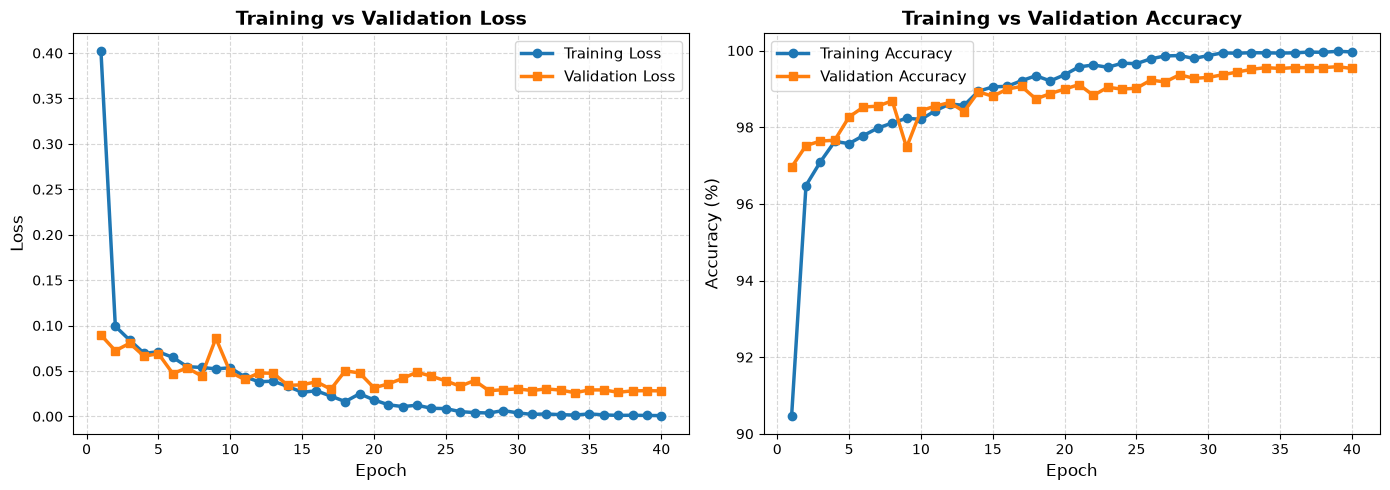

In [28]:
# ============================================================
# Cell 19 : Plot Training Curves
# ============================================================

import matplotlib.pyplot as plt

# Retrieve history
train_loss = history["train_loss"]
val_loss = history["val_loss"]
train_acc = history["train_acc"]
val_acc = history["val_acc"]

epochs = range(1, len(train_loss) + 1)

plt.figure(figsize=(14, 5))

# ------------------------------------------------------------
# Loss Curve
# ------------------------------------------------------------
plt.subplot(1, 2, 1)

plt.plot(
    epochs,
    train_loss,
    marker='o',
    linewidth=2.5,
    label='Training Loss'
)

plt.plot(
    epochs,
    val_loss,
    marker='s',
    linewidth=2.5,
    label='Validation Loss'
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.title("Training vs Validation Loss", fontsize=14, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(fontsize=11)

# ------------------------------------------------------------
# Accuracy Curve
# ------------------------------------------------------------
plt.subplot(1, 2, 2)

plt.plot(
    epochs,
    train_acc,
    marker='o',
    linewidth=2.5,
    label='Training Accuracy'
)

plt.plot(
    epochs,
    val_acc,
    marker='s',
    linewidth=2.5,
    label='Validation Accuracy'
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Accuracy (%)", fontsize=12)
plt.title("Training vs Validation Accuracy", fontsize=14, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(fontsize=11)

plt.tight_layout()
plt.show()

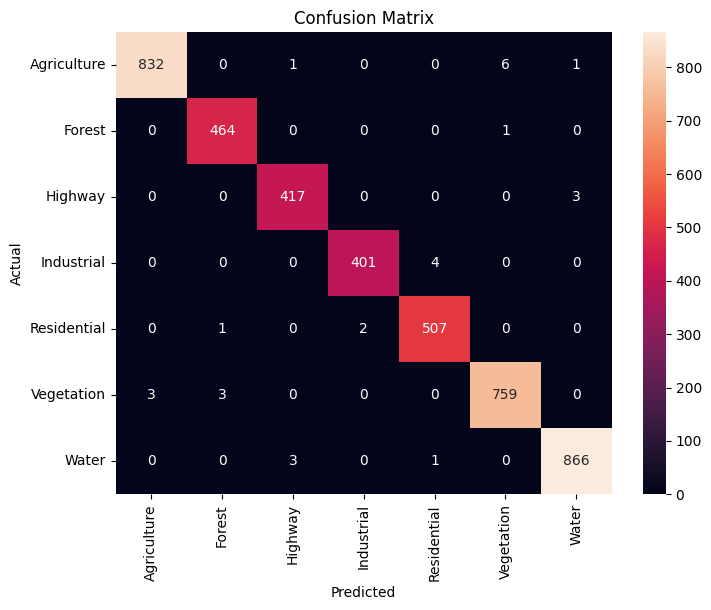

In [ ]:
# ============================================================
# CONFUSION MATRIX
# ============================================================

import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    all_labels,
    all_preds
)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("Confusion Matrix")

plt.show()

In [ ]:
# ============================================================
# CLASSIFICATION REPORT
# ============================================================

report = classification_report(
    all_labels,
    all_preds,
    target_names=CLASS_NAMES
)

print(report)

              precision    recall  f1-score   support

 Agriculture       1.00      0.99      0.99       840
      Forest       0.99      1.00      0.99       465
     Highway       0.99      0.99      0.99       420
  Industrial       1.00      0.99      0.99       405
 Residential       0.99      0.99      0.99       510
  Vegetation       0.99      0.99      0.99       765
       Water       1.00      1.00      1.00       870

    accuracy                           0.99      4275
   macro avg       0.99      0.99      0.99      4275
weighted avg       0.99      0.99      0.99      4275



In [ ]:
!pip install grad-cam -q

In [ ]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

import matplotlib.pyplot as plt
import numpy as np
import cv2

In [ ]:
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(device)

cuda


In [ ]:
model.load_state_dict(
    torch.load(
        os.path.join(OUTPUT_DIR, "best_efficientnetv2s.pth"),
        map_location=device
    )
)

model = model.to(device)
model.eval()

print("Model Loaded Successfully")

Model Loaded Successfully


In [ ]:
target_layers = [model.blocks[-1]]

In [ ]:
idx_to_class = {
    0: "Agriculture",
    1: "Forest",
    2: "Highway",
    3: "Industrial",
    4: "Residential",
    5: "Vegetation",
    6: "Water"
}

In [ ]:
sample_img, sample_label = test_dataset[0]

input_tensor = sample_img.unsqueeze(0).to(device)

print("Class:", idx_to_class[int(sample_label)])

Class: Residential


In [ ]:
cam = GradCAM(
    model=model,
    target_layers=target_layers
)

targets = [ClassifierOutputTarget(int(sample_label))]

grayscale_cam = cam(
    input_tensor=input_tensor,
    targets=targets
)

grayscale_cam = grayscale_cam[0]

print(grayscale_cam.shape)

(224, 224)


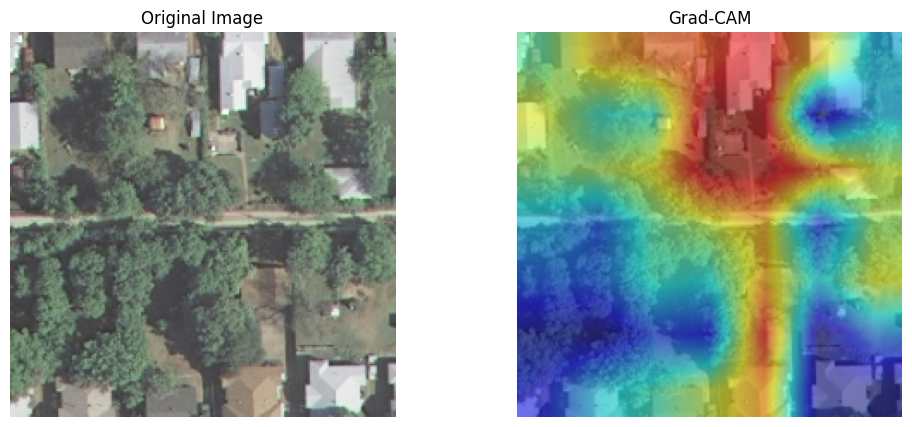

In [ ]:
img = sample_img.permute(1,2,0).cpu().numpy()

mean = np.array([0.485,0.456,0.406])
std  = np.array([0.229,0.224,0.225])

img = std * img + mean
img = np.clip(img,0,1)

visualization = show_cam_on_image(
    img,
    grayscale_cam,
    use_rgb=True
)

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(visualization)
plt.title("Grad-CAM")
plt.axis("off")

plt.show()

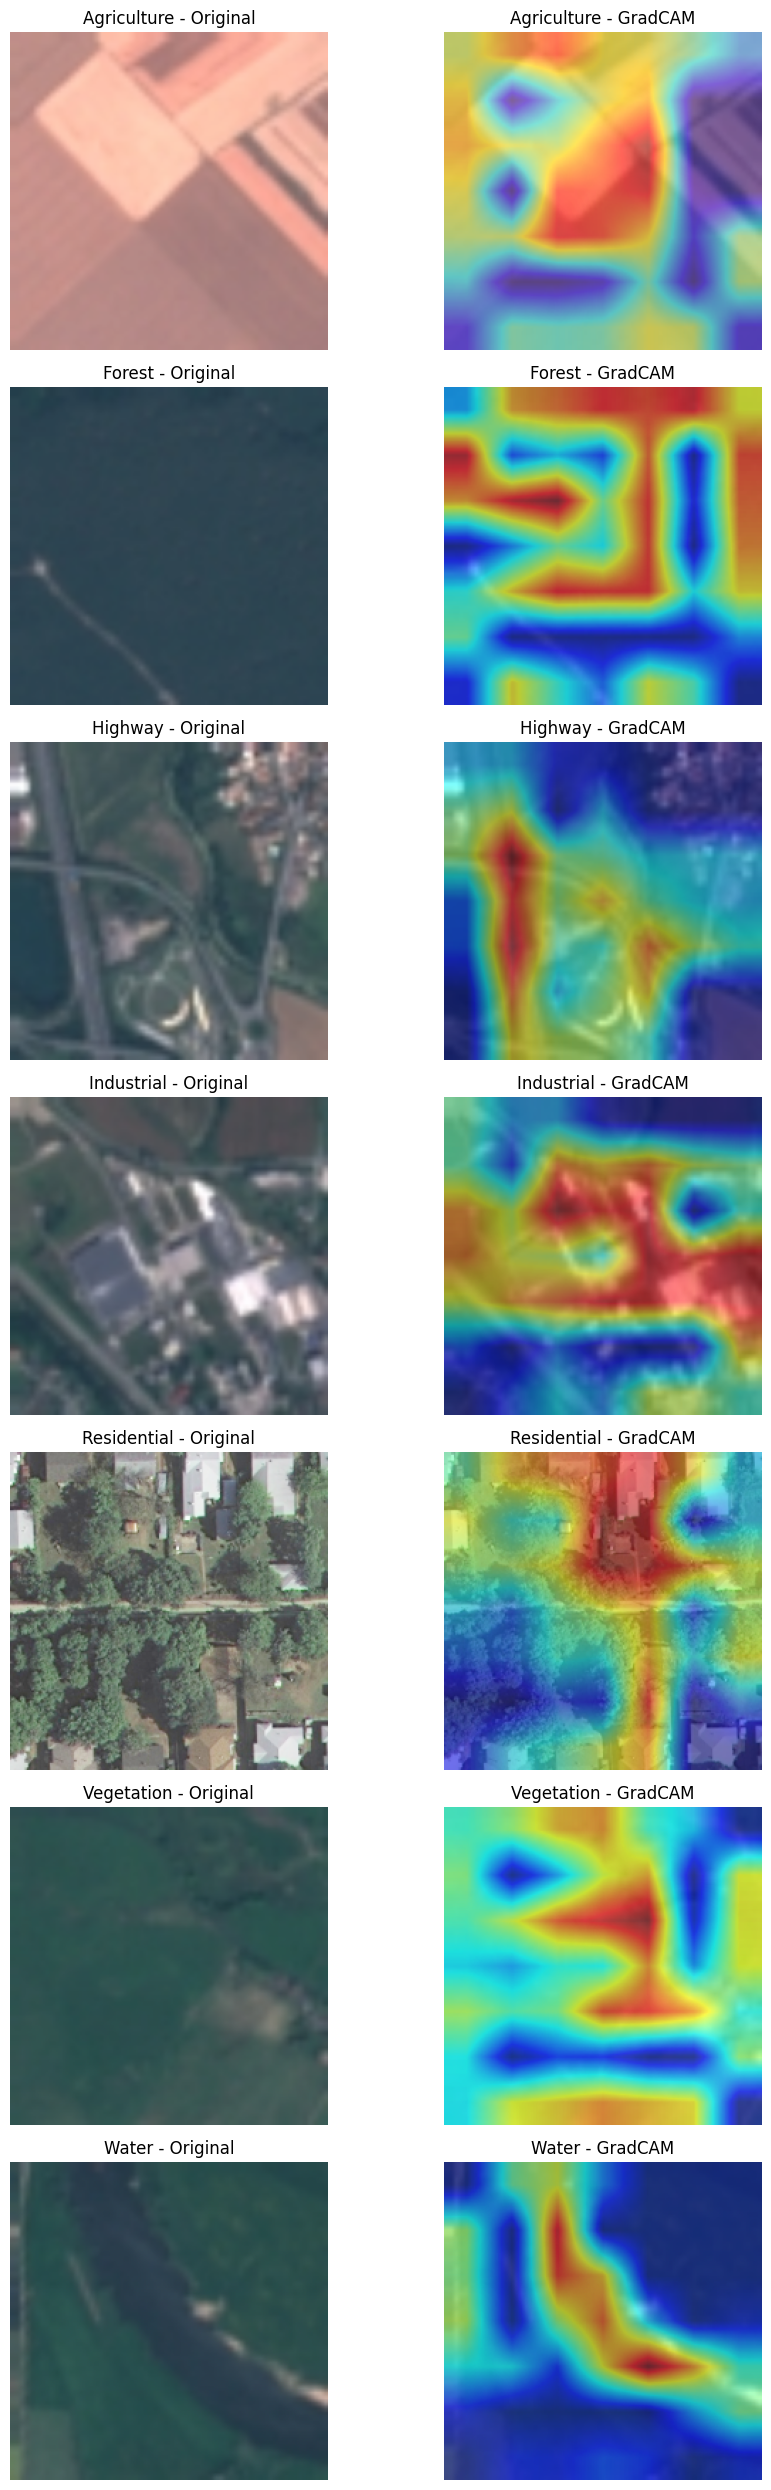

In [ ]:
import matplotlib.pyplot as plt
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

cam = GradCAM(
    model=model,
    target_layers=target_layers
)

fig, axes = plt.subplots(7, 2, figsize=(10, 25))

for class_id in range(7):

    for idx in range(len(test_dataset)):

        img, label = test_dataset[idx]

        if int(label) == class_id:

            input_tensor = img.unsqueeze(0).to(device)

            targets = [ClassifierOutputTarget(class_id)]

            grayscale_cam = cam(
                input_tensor=input_tensor,
                targets=targets
            )[0]

            image_np = img.permute(1,2,0).cpu().numpy()

            mean = np.array([0.485,0.456,0.406])
            std = np.array([0.229,0.224,0.225])

            image_np = std * image_np + mean
            image_np = np.clip(image_np,0,1)

            cam_image = show_cam_on_image(
                image_np,
                grayscale_cam,
                use_rgb=True
            )

            axes[class_id,0].imshow(image_np)
            axes[class_id,0].set_title(
                f"{idx_to_class[class_id]} - Original"
            )
            axes[class_id,0].axis("off")

            axes[class_id,1].imshow(cam_image)
            axes[class_id,1].set_title(
                f"{idx_to_class[class_id]} - GradCAM"
            )
            axes[class_id,1].axis("off")

            break

plt.tight_layout()
plt.show()